# 00 · Start here — your first machine learning demo

**The problem.** We know an apartment’s size. Can we use it to guess the
apartment’s value in AED?

**The example.** We’ll take 20 Dubai apartments from the supplied property
valuations. We’ll learn from 12 older examples, compare two guesses on
four later examples, and check the chosen method on four more.

**How to run it.** Read each explanation, then click the code cell below
it and press **Shift + Enter**. Start at the top.

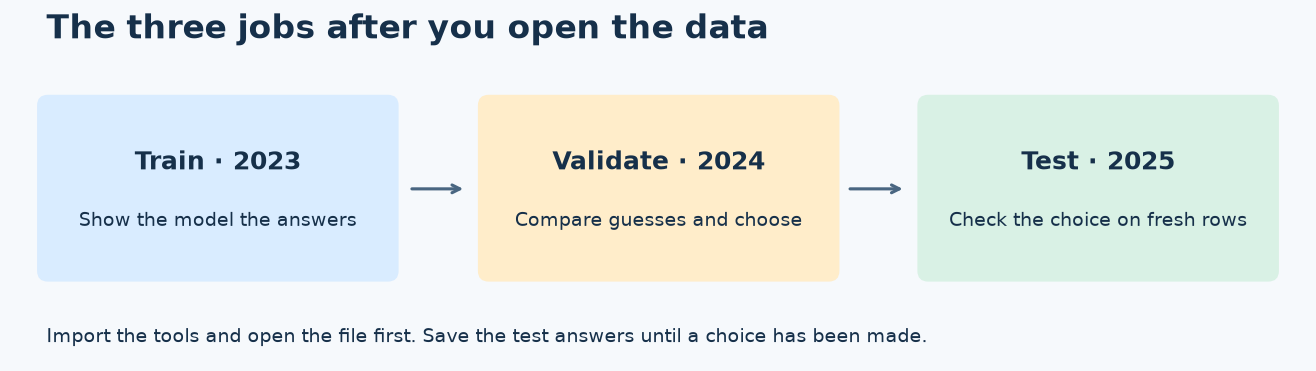

## 1 · Import the tools

**What we’re doing.** Load a tool for working with tables and a tool for drawing the prediction line.

**Why we’re doing it.** Import means make a tool available to this notebook. It is how Python gets the commands we’ll use next.

**What to look for.** The message says the tools are ready. The name pd is short for pandas.

In [1]:
import pandas as pd
from sklearn.linear_model import LinearRegression

print("Tools ready")

Tools ready


## 2 · Open the course file

**What we’re doing.** Run the prepared file-opening code and show three Dubai apartment rows.

**Why we’re doing it.** Before we build anything, we need to know what a row means and which columns we can use.

**What to look for.** Each row is a valuation. Size is what we know. Valuation is the recorded answer.

In [2]:
from pathlib import Path

current_folder = Path.cwd()
data_folder = next(
    (folder / "data" for folder in (current_folder, *current_folder.parents)
     if (folder / "data" / "property_valuations.csv").is_file()),
    None,
)
if data_folder is None:
    raise FileNotFoundError("Open the extracted course folder in Jupyter or VS Code.")

columns = ["valuation_date", "property_type", "emirate", "size_sqft", "valuation_aed"]
properties = pd.read_csv(data_folder / "property_valuations.csv", usecols=columns, parse_dates=["valuation_date"])
dubai = properties[properties["emirate"] == "Dubai"]
dubai = dubai.query("size_sqft > 0 and valuation_aed > 0")
apartments = dubai[dubai["property_type"] == "Apartment"]

apartments[["valuation_date", "size_sqft", "valuation_aed"]].head(3)

,valuation_date,size_sqft,valuation_aed
0,2018-01-01,1211.0,445000.0
2,2018-01-01,2055.0,4420000.0
5,2018-01-01,798.0,388000.0


## 3 · Split the rows into three groups

**What we’re doing.** Take a few rows from each year. You’ll fit on 2023, choose on 2024, and check once on 2025.

**Why we’re doing it.** We want to guess a later value. Rows from later years give us a more realistic check of that job.

**What to look for.** The sets have 12, 4 and 4 rows. Set means group of rows.

In [3]:
train = apartments[apartments["valuation_date"].dt.year == 2023].sample(12, random_state=42)
validate = apartments[apartments["valuation_date"].dt.year == 2024].sample(4, random_state=42)
test = apartments[apartments["valuation_date"].dt.year == 2025].sample(4, random_state=42)

print("Training rows:", len(train))
print("Validation rows:", len(validate))
print("Test rows:", len(test))

Training rows: 12
Validation rows: 4
Test rows: 4


## 4 · Choose the input and the answer

**What we’re doing.** Give the model apartment size and the recorded training value.

**Why we’re doing it.** Size is the clue available before the guess. Recorded value is the answer the model learns from.

**What to look for.** An input is also called a feature. The answer column is also called the target.

In [4]:
training_sizes = train[["size_sqft"]]
training_values = train["valuation_aed"]

train[["size_sqft", "valuation_aed"]].head(3)

,size_sqft,valuation_aed
140750,1653.0,1304000.0
138571,1136.0,903000.0
143590,766.0,897000.0


Two brackets keep the sizes as a table with one column. One pair of
brackets takes out the answer column. A common name for the input
table is **X**. A common name for the answers is **y**.

## 5 · Train a line

**What we’re doing.** Create a straight-line model and let it learn from the 12 examples.

**Why we’re doing it.** A straight line lets us turn a property size into a predicted number. Predicting a number is called regression.

**What to look for.** The word fit means learn. The model learns how to draw its line using the training inputs and known answers.

In [5]:
line = LinearRegression()
line.fit(training_sizes, training_values)
print("The line has learned from the 12 training apartments.")

The line has learned from the 12 training apartments.


## 6 · Predict values for validation

**What we’re doing.** Give the line the sizes of four validation apartments. Put its guesses beside the recorded values.

**Why we’re doing it.** A prediction uses the clue we could know in advance. We read the recorded answer afterwards to check the guess.

**What to look for.** The word predict means make a guess using what was learned. It receives only the input column.

In [6]:
guesses = line.predict(validate[["size_sqft"]])
comparison = validate[["size_sqft", "valuation_aed"]].copy()
comparison["predicted_aed"] = guesses.round()
comparison

,size_sqft,valuation_aed,predicted_aed
174053,1909.0,3315000.0,1540656.0
169715,1064.0,674000.0,1033540.0
167632,960.0,775000.0,971126.0
168141,856.0,1649000.0,908712.0


## 7 · Validate and choose which guess to use

**What we’re doing.** Compare the line with a simpler guess that always predicts the middle training value.

**Why we’re doing it.** We need a starting point to judge whether the learned line helped. The validation rows are where we make that choice.

**What to look for.** Smaller is better. In this example, the line misses by less on average.

In [7]:
middle_value = training_values.median()
simple_miss = (validate["valuation_aed"] - middle_value).abs().mean()
line_miss = (validate["valuation_aed"] - guesses).abs().mean()

print(f"Middle-value guess · average miss AED {simple_miss:,.0f}")
print(f"Line · average miss AED {line_miss:,.0f}")

Middle-value guess · average miss AED 878,750
Line · average miss AED 767,575


**How we counted the miss.** If a guess is AED 20,000 too high or AED 20,000
too low, its absolute error is AED 20,000. The average of these misses is
called **mean absolute error**, or **MAE**.

## 8 · Test the choice once

**What we’re doing.** Take the line we chose on validation and make guesses for the four 2025 rows.

**Why we’re doing it.** The 2025 rows give us a fresh check. Keeping them aside lets us measure the chosen method fairly.

**What to look for.** Read the average miss in AED. Four rows are enough to practise the steps. Performance estimates need more examples.

In [8]:
test_guesses = line.predict(test[["size_sqft"]])
test_miss = (test["valuation_aed"] - test_guesses).abs().mean()

print(f"Final test · average miss AED {test_miss:,.0f}")

Final test · average miss AED 915,058


### Say it in your own words

Which rows taught the line? Which rows helped us choose it? Which rows
supplied the final check?

Continue with [01 · Regression and classification](01_Regression_and_Classification.ipynb),
[02 · KNN and SVM](02_KNN_and_SVM_Classifiers.ipynb), and
[03 · K-fold cross-validation](03_K_Fold_Cross_Validation.ipynb).
The [D2.1 demo](D2.1_Training_Discipline.ipynb) repeats this workflow on a larger sample.